# Spooky Season Escapes; What to Expect When Flying in October

Kylie King (Georgetown University, Data Science and Analytics (DSAN))  
November 20, 2026

## Traveling in October

October is considered a ‘shoulder season’ in most vacation destinations. It is situated between the summer and winter vacation seasons, perfectly in the middle of the back-to-school rush. For most families and students, October is not an ideal time to be traveling. For others, October is the perfect time to secure discounted hotels or visit popular destinations with less crowds. Whether inviting or inconvenient, what does air travel look like during this shoulder season month?

To answer this question, we looked at United States flight records from October 2024. The Department of Transportation provides Airline On-Time Performance datasets through the [TranStats portal](https://www.transtats.bts.gov/). By creating and querying a database for flights in October 2024, we evaluate the busiest time of October to travel, the most reliable airlines to take in October, and the risks of flight cancellation.

## Avoiding the Crowds

[InsureMyTrip analyzed TSA data](https://www.insuremytrip.com/travel-advice/travel-planning/best-worst-time-to-fly-report/) from 2023 to 2026, and found that, on average, the busiest day to fly is Sunday, and the least busy day is Tuesday. How does that yearly average compare to October?

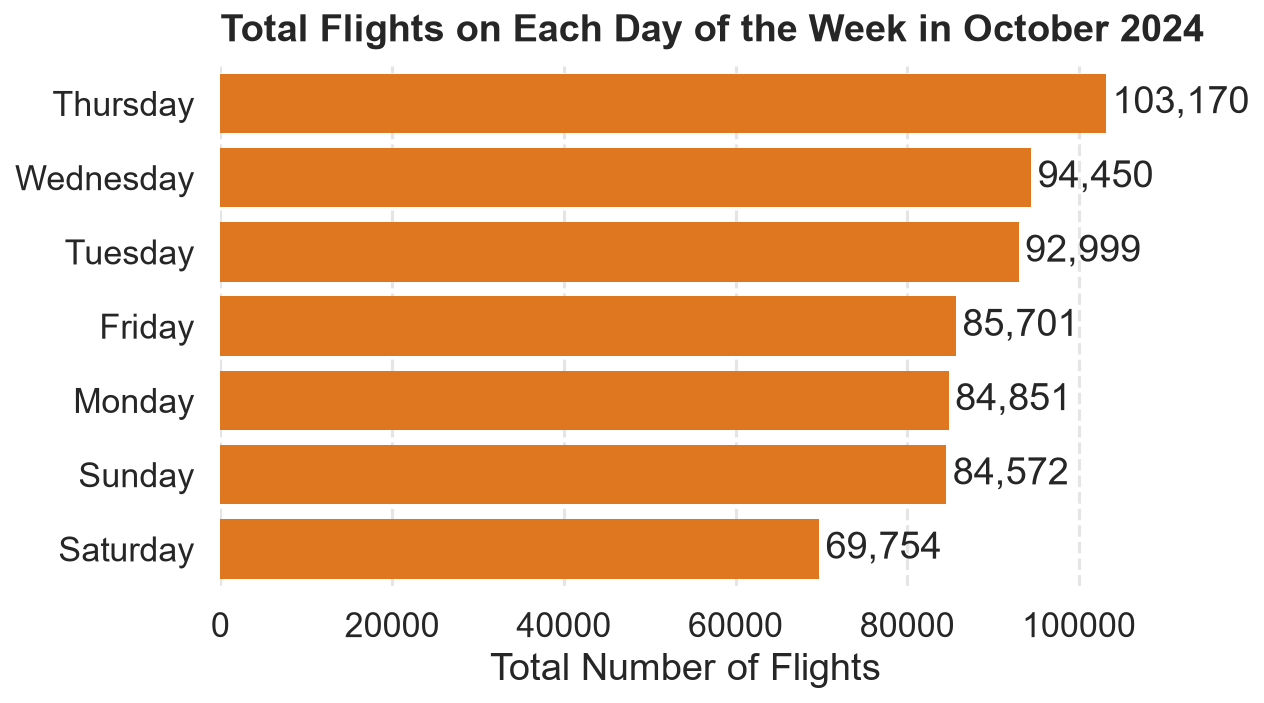

In [1]:
# busiest days
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

weekday_df = pd.read_csv(r"data/kylie_king_kk1543_hw4_problem_03_result.csv")

weekday_df = weekday_df.drop(weekday_df.index[-1]) #removing an 'unknown' date flight

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)

sns.barplot(
    data=weekday_df,
    x="Flight_Count",
    y="Day",
    color="#ff7300",
    edgecolor="none",
    ax=ax,
)

ax.set_title("Total Flights on Each Day of the Week in October 2024", loc="left", fontweight="bold", pad=12)
ax.set_xlabel("Total Number of Flights")
ax.set_ylabel("")
ax.xaxis.grid(True, linestyle="--", alpha=0.5)
ax.yaxis.grid(False)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
sns.despine(left=True, bottom=True)

With 103,170 flights over the course of October 2024, Thursday is actually the busiest day to fly in October! The slowest day to fly in October is Saturday, which had 69,574 flights in October 2024. Sunday, which is typically seen as the busiest day to fly, only had 84,572 flights in October 2024, making it the second slowest day of the month. Tuesday, which is typically seen as the slowest day to fly, had 92,999 flights in October 2024, making it the third busiest day of the month. This is important to keep in mind when traveling in October, as it directly contradicts the ‘common knowledge’ of flight booking.

It is important to keep in mind, however, that the time of month can also change how busy the airports are. One must consider holidays, long weekends, or other popular travel times. In October 2024, for example, the last week of the month saw significantly fewer flights across all days. In addition, October 31st, the last day of the month, had the second fewest flights of the entire month! This decline in flights is likely because the 31st is Halloween, a fairly popular holiday.

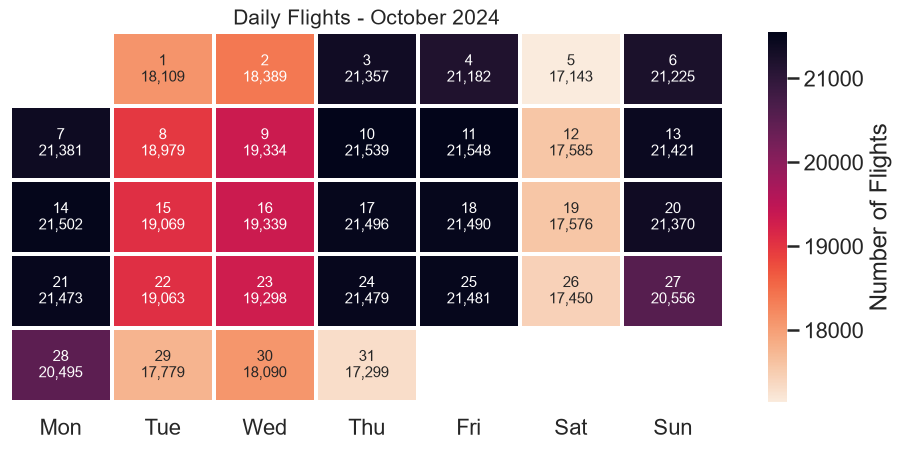

In [2]:
#making a really cool calendar visual
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import calendar

month_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_7_result.csv")
sns.set_theme(style="white", context="talk")

# making sure these are in datetime
month_df['FlightDate'] = pd.to_datetime(month_df['FlightDate'])

#calendar for october 2024
cal = calendar.monthcalendar(2024, 10)

calendar_data = np.full((len(cal), 7), np.nan)
annotations = np.full((len(cal), 7), '', dtype=object)

for week_idx, week in enumerate(cal):
    for day_idx, day in enumerate(week):
        if day != 0:
            flight_count = month_df.loc[
                month_df['FlightDate'].dt.day == day,
                'Flight_Count'
            ]

            count = flight_count.iloc[0] if not flight_count.empty else 0

            calendar_data[week_idx, day_idx] = count

            # date, then number of flights
            annotations[week_idx, day_idx] = f"{day}\n{count:,.0f}"
            

plt.figure(figsize=(12, 5))

sns.heatmap(
    calendar_data,
    annot=annotations,
    fmt='',
    cmap='rocket_r',
    linewidths=3,
    linecolor='white',
    cbar_kws={'label': 'Number of Flights'},
    xticklabels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'],
    yticklabels=False,
    annot_kws={'fontsize': 11}
)

plt.title('Daily Flights - October 2024', fontsize=16)
plt.xlabel('')
plt.ylabel('')
plt.show()

When traveling in October, keep these findings in mind:

-   Thursday is the busiest day to fly, and Saturday is the least busy.
-   The last week of the month is less busy than other weeks.
-   Halloween is one of the least busy days of the month to fly.

## Most Reliable Airlines

[The Points Guy](https://thepointsguy.com/airline/best-us-airlines-2026) created a report on the best US airlines in 2026. The report found that Delta Air Lines was the best, as it scored high on on-time performance, few involuntary bumps, lounges, and customer experience. The full rankings were:

1.  Delta Air Lines
2.  United Airlines
3.  Southwest Airlines
4.  Alaska Air Group
5.  American Airlines
6.  JetBlue
7.  Allegiant Air
8.  Frontier Airlines

The Points Guy report is very thorough, with multiple variables such as affordability, cabin features, loyalty programs, and destination options. However, it only includes the top 8 airlines of the 15 that regularly fly domestically in the US. When looking at all 15 airlines and their on-time performance, what are the most reliable airlines in October 2024?

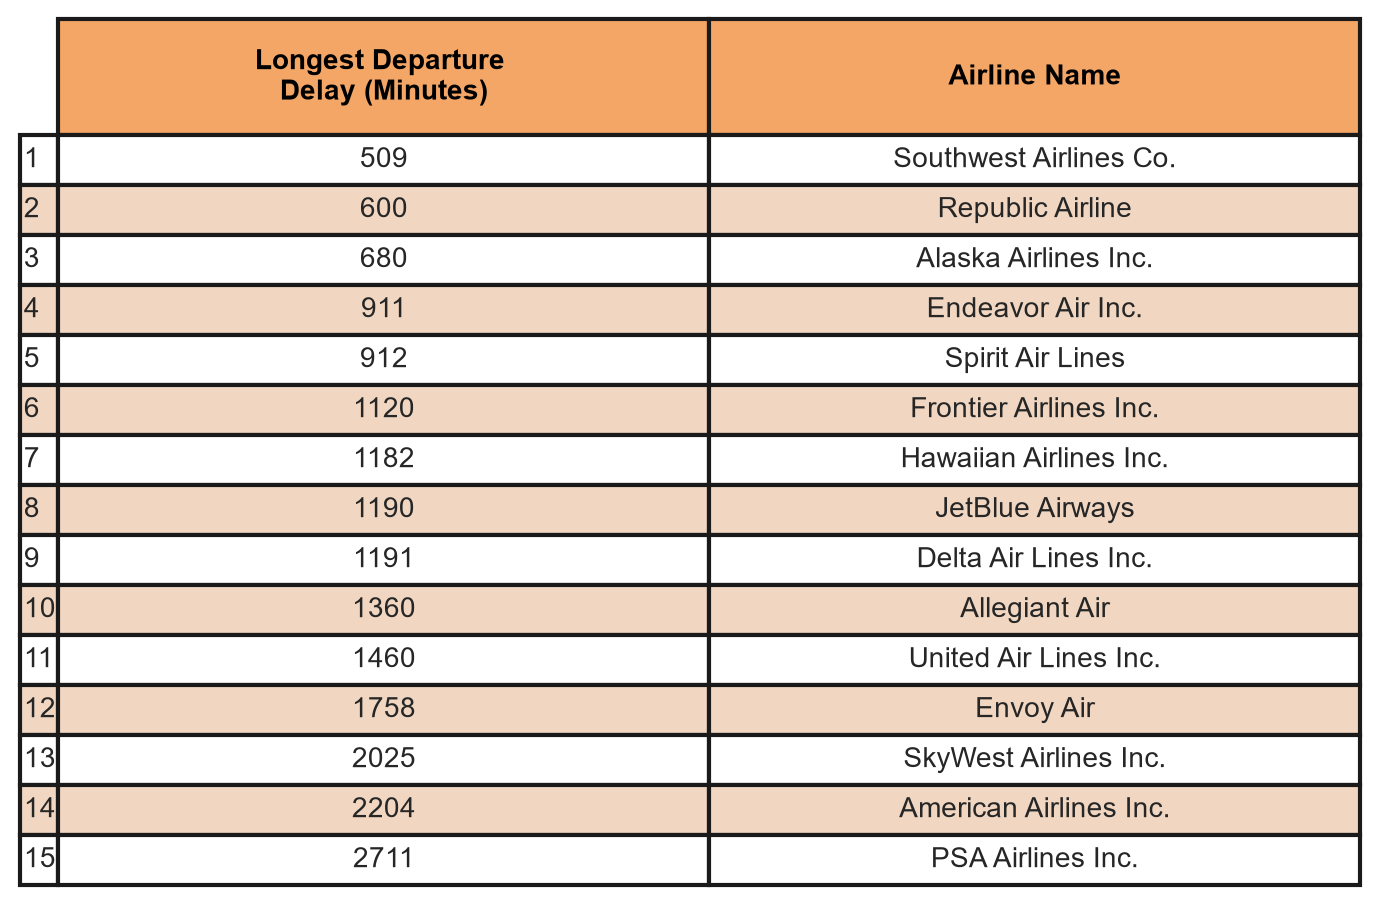

In [3]:
# airline with longest delay
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from plottable import Table

max_delay_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_01_result.csv")
max_delay_df.index = range(1, len(max_delay_df) + 1)
max_delay_df.index.name = "Rank"

#simplify airline names
max_delay_df["Airline_Name"] = max_delay_df["Airline_Name"].str.split(":").str[0].str.strip()

#changing names for display
max_delay_df = max_delay_df.rename(columns={
    'Airline_Name': 'Airline Name',
    'Max_Departure_Delay': 'Longest Departure \nDelay (Minutes)',
})

fig, ax = plt.subplots( dpi=200)
ax.axis('off')

table = ax.table(
    cellText=max_delay_df.values,
    colLabels=max_delay_df.columns,
    rowLabels=max_delay_df.index,
    loc='center',
    cellLoc='center'
)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        # Header
        cell.set_facecolor('#f4a666')
        cell.set_text_props(color='black', weight='bold'),
        cell.set_height(0.1)
    elif row % 2 == 0:
        cell.set_facecolor('#f1d7c2')
    else:
        cell.set_facecolor('white')

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)

plt.show()

The airline with the longest departure delay in all of October 2024 was PSA Airlines Inc., with a 2711 minute departure delay, about 45 hours. By contrast, Southwest Airlines’ longest departure delay was 509 minutes, or roughly 8.5 hours. Unfortunately, this is not informative about the reliability of the airlines. It is more of an evaluation of the extreme circumstances that each airline faced in October 2024.

To get a clearer picture, we instead look at each airline’s longest average delay, and what airports those average delays occur at. At all other airports, each airline will have a lower average departure delay. This allows travelers to evaluate which airline to select based on their airport, while also understanding the longest average delay to expect from an airline.

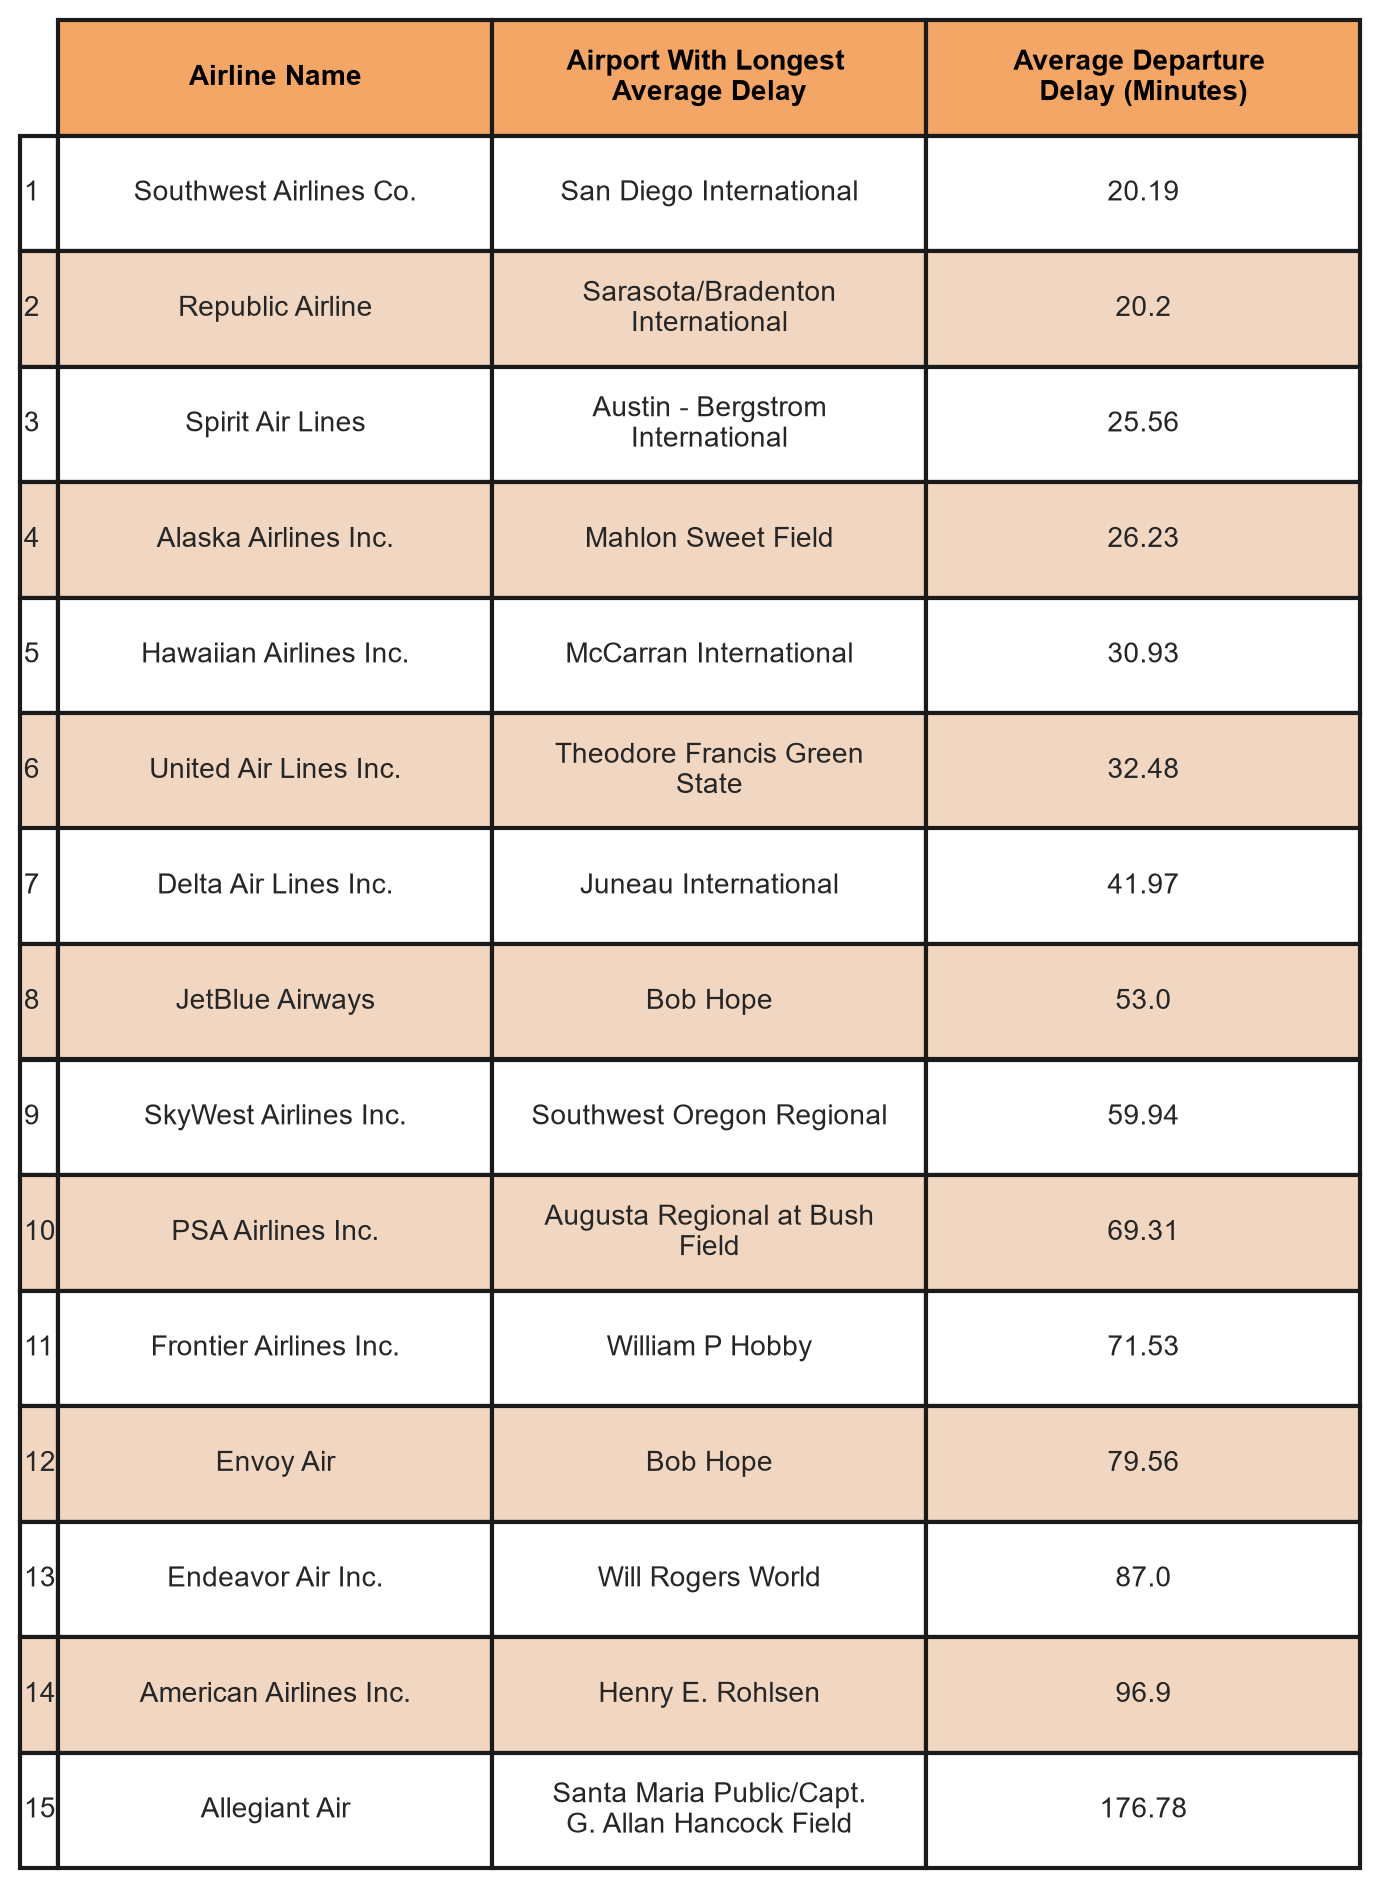

In [4]:
# airports and airlines
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from plottable import Table
import textwrap

airline_airport_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_05_result.csv")
airline_airport_df = airline_airport_df.sort_values(by="Avg_Departure_Delay", ascending=True)
#sort and rank
airline_airport_df.index = range(1, len(airline_airport_df) + 1)
airline_airport_df.index.name = "Rank"
#round departure delays
airline_airport_df["Avg_Departure_Delay"] = airline_airport_df["Avg_Departure_Delay"].round(2)
# simplify airline names
airline_airport_df["Airline_Name"] = airline_airport_df["Airline_Name"].str.split(":").str[0].str.strip()
#and airport names
airline_airport_df["Airport_Name"] = airline_airport_df["Airport_Name"].str.split(":").str[1].str.strip()

#wrapping text
airline_airport_df["Airport_Name"] = airline_airport_df["Airport_Name"].apply(
    lambda x: "\n".join(textwrap.wrap(str(x), width=25))
)

#changing names for display
airline_airport_df = airline_airport_df.rename(columns={
    'Airline_Name': 'Airline Name',
    'Avg_Departure_Delay': 'Average Departure \nDelay (Minutes)',
    'Airport_Name': 'Airport With Longest \nAverage Delay',
})



fig, ax = plt.subplots(dpi=200)
ax.axis('off')

table = ax.table(
    cellText=airline_airport_df.values,
    colLabels=airline_airport_df.columns,
    rowLabels=airline_airport_df.index,
    loc='center',
    cellLoc='center'
)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        # Header
        cell.set_facecolor('#f4a666')
        cell.set_text_props(color='black', weight='bold'),
        cell.set_height(0.1)
    elif row % 2 == 0:
        cell.set_facecolor('#f1d7c2')
        cell.set_height(0.1)
    else:
        cell.set_facecolor('white')
        cell.set_height(0.1)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)

plt.show()

Once again, Southwest Airlines is at the top of the list. Their longest average delay in October 2024 was 20.19 minutes out of San Diego International Airport. Flying out of any other airport, travelers can expect a lower average departure delay. Considering that their maximum departure delay in October 2024 was also the shortest of all the airlines, this suggests that Southwest is generally reliable, and may resolve extreme situations faster than other airlines.

Delta Air Lines, by comparison, has an average departure delay of 41.97 minutes out of Juneau International Airport. While Delta customers can expect shorter average delays out of all other airports, this is twice the length of Southwest’s longest average delay. In addition, Delta’s longest departure delay in all of October 2024 was 1190 minutes, or 19.8 hours, which is more than double Southwest Airlines’ longest delay of 8.5 hours. This suggests that, while Delta may have the amenities described in The Points Guy’s Best Airlines report, their on-time performance is actually lower than other airlines like Southwest, at least in October 2024.

At the bottom of the list, Allegiant Air has the longest average departure delay, with 176.78 minutes out of Santa Maria Public/Capt. G. Allan Hancock Field Airport. Allegiant Air is the only airline that flies out of the Santa Maria airport, and Santa Maria actually has the longest average delay of all airports in October 2024, with the same 176.78 minutes, or 2.93 hour, average delay.

While on-time performance is not the most important part of air travel, it is worth considering alongside other preferences like amenities and loyalty programs when selecting an airline.

When traveling in October, keep these findings in mind:

-   Southwest Airlines had the best on-time performance data in 2024, whereas Delta Air Lines, a popular airline, was in the middle of the ranking.
-   Santa Maria Public/Capt. G. Allan Hancock Field Airport and the Allegiance Air airline have the longest average delays in October 2024, at 176.78 minutes, or 2.93 hours.

## Cancellation Risks

On any trip, a cancellation could ruin the entire vacation. The website [DelayGuard](https://www.delayguard.ai/cancellation-rates) used the exact same Bureau of Transportation Statistics On-Time Performance dataset, looking across the full years 2024-2025. They found that 1.41% of flights in that time period were canceled. How does that average compare to just October?

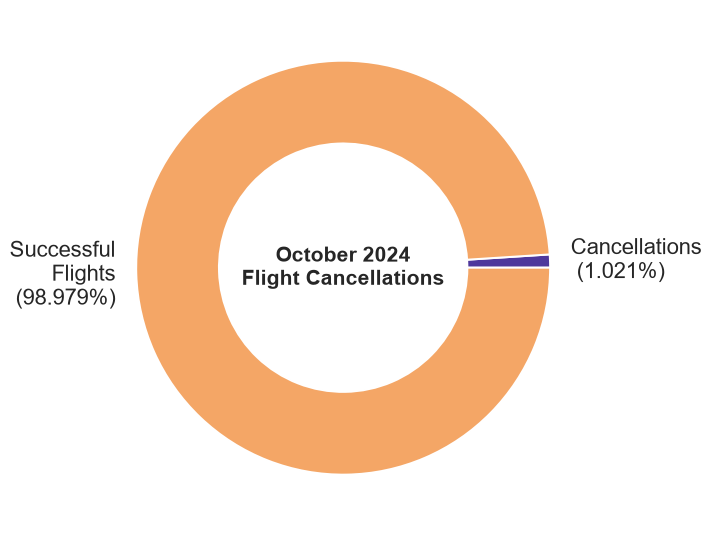

In [5]:
#pie chart of cancellations
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#data
cancel_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_6a_result.csv")
cancellations = cancel_df.at[0, 'Num_Cancelled_Flights']
total_scheduled_flights = weekday_df['Flight_Count'].sum()

plt.figure(figsize=(7, 7))
data = [cancellations, total_scheduled_flights-cancellations] 
total = sum(data)
percentages = [x / total * 100 for x in data]
labels = [
    f'Cancellations\n ({percentages[0]:.3f}%)',
    f'Successful\nFlights\n ({percentages[1]:.3f}%)'
]
colors = ['#4e389c','#f4a666']

plt.pie(data, labels=labels, colors=colors, wedgeprops={'width': 0.4})
plt.text(0, 0, 'October 2024\nFlight Cancellations', ha='center', va='center',
         fontsize=16, fontweight='bold')
plt.show() 

October 2024 had fewer flight cancellations than the average for the rest of the year! With only 1.021% of flights cancelled, a bit less than the 1.41% average, October may be a slightly more reliable time to fly than expected.

It is important to know what exactly causes these cancellations though, so that travelers can plan ahead and anticipate possible changes. At the 184 airports that experienced cancellations in October 2024, “Weather” was the most frequent cancellation reason by far. In the following map, “Weather” was reported as the most frequent cancellation reason for airports in 43 states, while airports in 3 states most frequently cited “Carrier” (issues within the airline), 2 states most frequently cited “National Air System” (issues like air traffic or airport operations), and 2 states (Kansas and Mississippi) saw no cancellations in October 2024.

In [6]:
# cancellation reasons by state
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

#data
causes_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_6b_result.csv")
causes_df['State'] = causes_df['Airport_Name'].str.extract(r',\s*([A-Z]{2}):')

#parse out state names
state_causes = (causes_df.groupby(['State', 'Most_Freq_Cancellation_Reason'])['Cancellation_Count'].sum().reset_index())

#pull the top cause for each state
top_causes = (state_causes.sort_values('Cancellation_Count', ascending=False).groupby('State').first().reset_index())
#KS and MS didn't have any cancellations, by chance
missing_states = pd.DataFrame({
    'State': ['MS', 'KS'],
    'Most_Freq_Cancellation_Reason': ['No Data', 'No Data'],
    'Cancellation_Count': [0, 0]
})

top_causes = pd.concat([top_causes, missing_states], ignore_index=True)

#choropleth

color_map = {
    'Weather': '#a691ef',
    'Carrier': '#e8c882',
    'National Air System': '#f4a666',
    'No Data': '#9f9f9f'
}

fig = px.choropleth(
    top_causes,
    locations='State',
    locationmode='USA-states',
    color='Most_Freq_Cancellation_Reason',
    hover_name='State',
    hover_data={
        'Most_Freq_Cancellation_Reason': True,
        'Cancellation_Count': False
    },
    scope='usa',
    color_discrete_map=color_map
)

fig.update_layout(
    geo=dict(showlakes=True, lakecolor='white'),
    autosize=True,
    height=None,
    width=None,
    margin=dict(l=0, r=0, t=50, b=50),
    legend=dict(
        orientation='h',
        yanchor='top',
        y=-0.1,
        xanchor='center',
        x=0.5,
        title_text=''
    ),
    title=dict(
        text='<b>Most Frequent Flight Cancellation Reason by State: October 2024</b>',
        x=0.5,
        xanchor='center',
        y=0.95,
        yanchor='top',
        font=dict(size=14)
    )
)

fig.show(config={'staticPlot': True, 'responsive': True})


When traveling in October, keep these findings in mind:

-   October has slightly fewer flight cancellations than expected when compared to the rest of the year.
-   If a flight is cancelled, it is most likely due to weather.
-   Keep an eye out for severe storms, tornadoes, hurricanes, or early snows when traveling in October to anticipate cancellations.

## Conclusion

Whether for business or pleasure, air travel in October can be pleasant and stress-free! If travelers have flexibility in their schedule, Saturdays will be the least busy in the airports. By contrast, Thursdays will typically be the most busy. If travelers want an especially laid-back trip, they might consider traveling during the last week of the month, or on Halloween itself.

If travelers are prioritizing flights with minimal delays, they may want to consider Southwest Airlines, which performed very well in October 2024, with a maximum average departure delay of only 20.19 minutes. Republic Airline, the now-liquidated Spirit Air Lines, Alaska Airlines, Hawaiian Airlines, and United Air LInes also had average departure delays under 35 minutes.

Most travelers will not have to worry about canceled flights in October. In October 2024, only 1.021% of flights were canceled, which is lower than the yearly average of 1.41%. However, weather is the most common reason for canceled flights in October, so travelers should keep an eye on severe storms, tornadoes, hurricanes, and early snow in the weeks before their flight.

Enjoy the autumn leaves, cool weather, and fewer crowds with a lovely October vacation!

> This project was completed for DSAN 6300: Database Systems and SQL in the Georgetown University MS in Data Science & Analytics (DSAN) program. The data for this project was loaded into a MySQL database using an AWS EC2 instance. The data was then queried with SQL to produce the displayed data, and assembled into a narrative format.

> The data for this project was the “Airline On-Time Performance Data” dataset for October 2024, collected by the Office of Airline Information, Bureau of Transportation Statistics (BTS), hosted on the TranStats data portal, and retrieved at <https://www.transtats.bts.gov/DatabaseInfo.asp?QO_VQ=EFD&QO_fu146_anzr=b0-gvzr&QO_anzr=Nv4yv0r%20b0-gvzr%20cr4s14zn0pr%20Qn6n&Yv0x=D>